# Greater Boston: bike + rapid-transit infrastructure and MBTA Communities districts

This notebook reads the GIS data in `data/`, harmonizes the coordinate systems, and subsets everything to the
greater Boston area so that

* the **entire** bike network (`Existing_Bike_Network_2022`, `RECREATION_BikeFacilities` and the `BIKETRAILS_ARC` trails within the study area) and MBTA rapid-transit network (`MBTA_ARC` lines + `MBTA_NODE` stations) are shown, and
* only the **districts** (`MBTA3A_DISTRICTS_POLY`) that contain / are near that infrastructure are kept.

Datasets used:

| Data | Source folder | Native CRS |
|---|---|---|
| Bike network (lines) | `data/Existing_Bike_Network_2022` | EPSG:3857 |
| Recreation bike facilities (lines, City of Cambridge area) | `data/RECREATION_BikeFacilities.shp` | EPSG:2249 (ftUS) |
| Statewide bike trails (lines) | `data/biketrails_arc/biketrails_arc` | EPSG:26986 |
| MassDOT roads / streets (lines, statewide) | `data/MassDOT_Roads_SHP` | EPSG:26986 |
| MBTA rapid-transit lines / stations | `data/mbta_rapid_transit` | EPSG:26986 |
| MBTA Communities (3A) districts | `data/MBTA3A` | EPSG:26986 |
| Town boundaries (context) | `data/townssurvey_shp` | EPSG:26986 |

Not used: `tlgdb_2019_a_25_ma.gdb` (Census TIGER polygons, not needed here) and `MBTA3A_PARCELS_POLY` /
`MBTA3A_TRANSIT_HALFM_RADII_POLY` (parcel-level / derived buffer layers).

In [7]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import box
from shapely.ops import linemerge, substring
import gis_functions as gis
warnings.filterwarnings("ignore", category=UserWarning)

DATA = Path("data")
# Massachusetts State Plane (Mainland), meters. Used by the MBTA / district / town layers.
CRS = "EPSG:26986"


## 1. Read the data
The bike network is in Web Mercator (EPSG:3857); everything is reprojected to EPSG:26986 so all layers line up.

In [8]:
bike = gpd.read_file(DATA / "Existing_Bike_Network_2022" / "Existing_Bike_Network_2022.shp")
bike2 = gpd.read_file("data/RECREATION_BikeFacilities.shp/RECREATION_BikeFacilities.shp")
trails = gpd.read_file(DATA / "biketrails_arc" / "biketrails_arc" / "BIKETRAILS_ARC.shp")  # statewide

lines = gpd.read_file(DATA / "mbta_rapid_transit" / "MBTA_ARC.shp")
stations = gpd.read_file(DATA / "mbta_rapid_transit" / "MBTA_NODE.shp")
districts = gpd.read_file(DATA / "MBTA3A" / "MBTA3A_DISTRICTS_POLY.shp")
towns = gpd.read_file(DATA / "townssurvey_shp" / "TOWNSSURVEY_POLY.shp")

for name, g in [("bike", bike), ("bike2", bike2), ("trails", trails), ("lines", lines), ("stations", stations), ("districts", districts), ("towns", towns)]:
    print(f"{name:10s} {len(g):5d} features  crs={g.crs.to_string():12s} geom={sorted(g.geom_type.dropna().unique())}")

bike        3166 features  crs=EPSG:3857    geom=['LineString', 'MultiLineString']
bike2        671 features  crs=PROJCS["NAD83 / Massachusetts Mainland (ftUS)",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",41],PARAMETER["central_meridian",-71.5],PARAMETER["standard_parallel_1",41.7166666666667],PARAMETER["standard_parallel_2",42.6833333333333],PARAMETER["false_easting",656166.666666667],PARAMETER["false_northing",2460625],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]] geom=['LineString', 'MultiLineString']
trails      8277 features  crs=EPSG:26986   geom=['LineString', 'MultiLineString']
lines        138 features  crs=EPSG:26986   geom=['LineString', 'MultiLineString']
stations     166 features  crs

## 2. Clean and harmonize
Drop empty geometries from the bike layers and reproject to a common CRS.

In [9]:
bike = bike[bike.geometry.notna() & ~bike.geometry.is_empty].to_crs(CRS)
bike2 = bike2[bike2.geometry.notna() & ~bike2.geometry.is_empty].to_crs(CRS)   # ftUS state plane -> meters
trails = trails[trails.geometry.notna() & ~trails.geometry.is_empty].to_crs(CRS)
lines, stations, districts, towns = (g.to_crs(CRS) for g in (lines, stations, districts, towns))
print(len(bike), len(bike2), len(trails), "bike / recreation / trail segments after dropping empty geometries")

3159 671 8277 bike / recreation / trail segments after dropping empty geometries


## 3. Define the study area
The area of interest is the bounding box of the Boston bike network, recreation bike facilities and MBTA network (the statewide trails layer is *not* used to set it, or the box would cover all of Massachusetts) (with a small margin), so nothing
is cut off. Districts and towns are then subset against it.

In [10]:
infra = pd.concat([bike.geometry, bike2.geometry, lines.geometry, stations.geometry], ignore_index=True)
minx, miny, maxx, maxy = infra.total_bounds
pad = 1500  # meters
study_area = box(minx - pad, miny - pad, maxx + pad, maxy + pad)
print("Infrastructure extent (m):", [round(v) for v in infra.total_bounds])

Infrastructure extent (m): [220392, 884241, 245043, 909753]


In [11]:
# Districts: keep every district that falls in the study area, and flag those that directly touch bike or train infrastructure.
districts_sub = districts[districts.intersects(study_area)].copy()
# Statewide bike trails: keep only the segments that fall in the study area
trails_sub = trails[trails.intersects(study_area)].copy()
print(f"{len(trails_sub)} of {len(trails)} trail segments in study area")

infra_union = pd.concat([bike.geometry, bike2.geometry, trails_sub.geometry, lines.geometry], ignore_index=True).union_all()
districts_sub["touches_infra"] = districts_sub.intersects(infra_union)

# Towns: keep towns intersecting the study area (context layer), dissolving multi-part towns into one row.
towns_sub = towns[towns.intersects(study_area)].dissolve(by="TOWN", as_index=False)[["TOWN", "geometry"]]

print(f"{len(districts_sub)} districts in study area, {districts_sub.touches_infra.sum()} touch bike/train infrastructure")
print(f"{districts_sub.MUNI.nunique()} municipalities with districts; {len(towns_sub)} towns in study area")
districts_sub[["MUNI", "ZONENAM", "ZONABBR", "STATUS", "DU_CAP", "touches_infra"]].head()

4336 of 8277 trail segments in study area
125 districts in study area, 64 touch bike/train infrastructure
25 municipalities with districts; 40 towns in study area


,MUNI,ZONENAM,ZONABBR,STATUS,DU_CAP,touches_infra
12,Arlington,CorridorBroadway,CorBw,Compliant,0,False
13,Arlington,CorridorMassAveEast,CorE,Compliant,0,True
14,Arlington,CorridorMassAveHeights,CorH,Compliant,0,True
15,Arlington,NbhdMulti_East,NME,Compliant,0,False
16,Arlington,NbhdMulti_Heights,NMH,Compliant,0,False


### Streets (MassDOT roads)
`EOTROADS_ARC` is a large statewide layer (~410,000 segments, 95 MB). Rather than loading all of it, only the features
whose bounding box intersects the study area are read (`bbox=`), so the map boundaries stay exactly the same as before.
The roads are **not** used to define the study area or the "touches infrastructure" flag for districts (streets are everywhere, so every district would be flagged).

In [12]:
ROAD_COLS = ["STREETNAME", "CLASS", "ADMIN_TYPE", "RT_NUMBER", "RDTYPE", "F_CLASS", "NUM_LANES", "SPEED_LIM",
             "MGIS_TOWN", "COUNTY", "AADT", "LENGTH_MI"]

roads_sub = gpd.read_file(
    DATA / "MassDOT_Roads_SHP" / "EOTROADS_ARC.shp",
    bbox=study_area.bounds,          # same study area as every other layer
    columns=ROAD_COLS,
).to_crs(CRS)
roads_sub = roads_sub[roads_sub.geometry.notna() & ~roads_sub.geometry.is_empty & roads_sub.intersects(study_area)].copy()

print(f"{len(roads_sub)} road segments in study area, {roads_sub.LENGTH_MI.sum():,.0f} miles")
roads_sub.head()

59657 road segments in study area, 4,828 miles


,STREETNAME,CLASS,ADMIN_TYPE,RT_NUMBER,RDTYPE,F_CLASS,NUM_LANES,SPEED_LIM,MGIS_TOWN,COUNTY,AADT,LENGTH_MI,geometry
0,PACELLA PARK DRIVE,5,0,NaN,5,0,0,0,RANDOLPH,21,0,0.035725,"LINESTRING (237063.94 883948.684, 237063.085 8..."
1,NaN,6,0,NaN,6,0,0,0,WINCHESTER,17,0,0.035608,"LINESTRING (228661.408 909840.361, 228669.346 ..."
2,DERNE STREET,5,0,NaN,5,0,0,0,BOSTON,25,0,0.011626,"LINESTRING (236000.102 901088.706, 236003.05 9..."
3,CHARLES RIVER SQUARE,5,0,NaN,5,0,0,0,BOSTON,25,0,0.036338,"LINESTRING (235318.086 901112.136, 235318.273 ..."
4,GROVE PLACE,5,0,NaN,5,0,0,0,BOSTON,25,0,0.023935,"LINESTRING (235528.351 901197.297, 235510.639 ..."


Note: the bike network covers only the City of Boston, and Boston has no `MBTA3A` districts, so the districts
appear in the surrounding cities and towns rather than in the city core.

In [13]:
# Districts by municipality
(districts_sub.groupby("MUNI")
     .agg(districts=("ZONECOD", "count"), touching_infra=("touches_infra", "sum"))
     .sort_values("districts", ascending=False))

,districts,touching_infra
MUNI,,
Cambridge,22,22
Milton,20,2
Brookline,10,8
Belmont,8,5
Revere,7,4
Malden,6,4
Newton,6,4
Needham,6,0
Arlington,5,2


## 4. Map

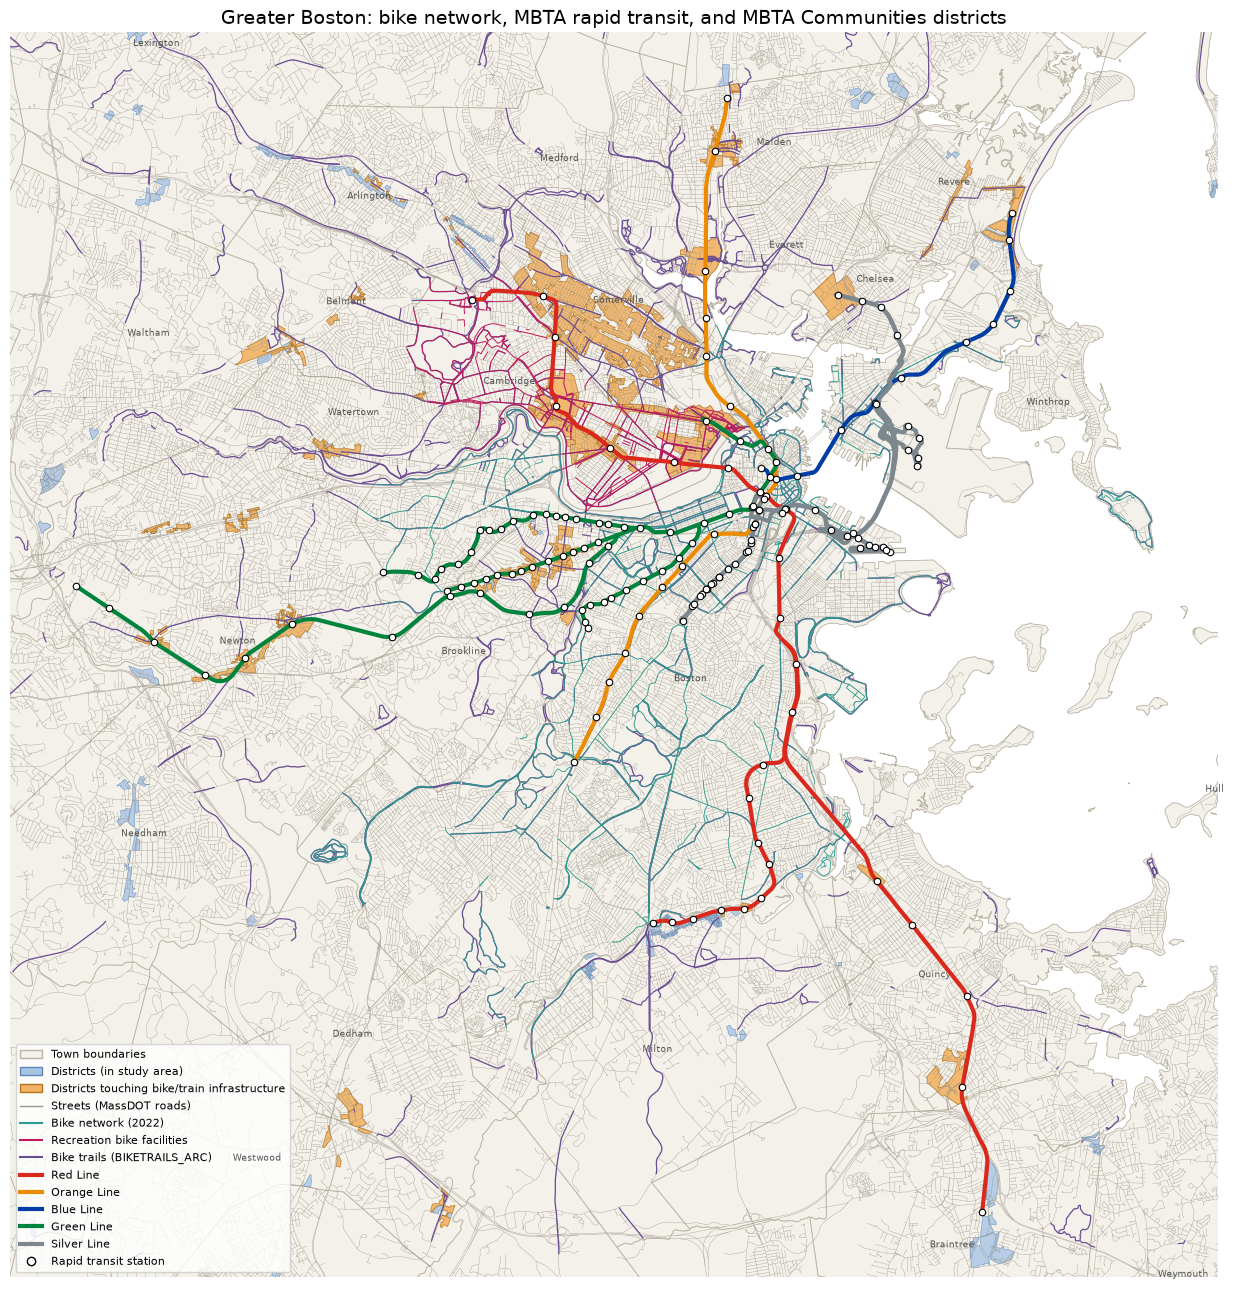

In [14]:
LINE_COLORS = {"RED": "#DA291C", "ORANGE": "#ED8B00", "BLUE": "#003DA5", "GREEN": "#00843D", "SILVER": "#7C878E"}

fig, ax = plt.subplots(figsize=(13, 13))

towns_sub.plot(ax=ax, facecolor="#f4f1ea", edgecolor="#b8b2a3", linewidth=0.6, zorder=1)

districts_sub[~districts_sub.touches_infra].plot(ax=ax, facecolor="#a8c5e6", edgecolor="#5b86b5", linewidth=0.4, alpha=0.8, zorder=2)
districts_sub[districts_sub.touches_infra].plot(ax=ax, facecolor="#f2b263", edgecolor="#b8741a", linewidth=0.5, alpha=0.9, zorder=3)

roads_sub.plot(ax=ax, color="#9a958a", linewidth=0.25, zorder=3.5)
trails_sub.plot(ax=ax, color="#6a4c93", linewidth=0.9, zorder=4)
bike.plot(ax=ax, color="#2a9d8f", linewidth=0.6, zorder=4)
bike2.plot(ax=ax, color="#c2185b", linewidth=0.7, zorder=4)

for line, color in LINE_COLORS.items():
    lines[lines.LINE == line].plot(ax=ax, color=color, linewidth=3, zorder=5)
stations.plot(ax=ax, color="white", edgecolor="black", markersize=22, linewidth=0.8, zorder=6)

# Town labels
for _, row in towns_sub.iterrows():
    p = row.geometry.representative_point()
    ax.annotate(row.TOWN.title(), (p.x, p.y), ha="center", fontsize=6.5, color="#555", zorder=7)

ax.set_xlim(study_area.bounds[0], study_area.bounds[2])
ax.set_ylim(study_area.bounds[1], study_area.bounds[3])
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Greater Boston: bike network, MBTA rapid transit, and MBTA Communities districts", fontsize=14)

handles = [
    Patch(facecolor="#f4f1ea", edgecolor="#b8b2a3", label="Town boundaries"),
    Patch(facecolor="#a8c5e6", edgecolor="#5b86b5", label="Districts (in study area)"),
    Patch(facecolor="#f2b263", edgecolor="#b8741a", label="Districts touching bike/train infrastructure"),
    Line2D([], [], color="#9a958a", lw=1, label="Streets (MassDOT roads)"),
    Line2D([], [], color="#2a9d8f", lw=1.5, label="Bike network (2022)"),
    Line2D([], [], color="#c2185b", lw=1.5, label="Recreation bike facilities"),
    Line2D([], [], color="#6a4c93", lw=1.5, label="Bike trails (BIKETRAILS_ARC)"),
    *[Line2D([], [], color=c, lw=3, label=f"{n.title()} Line") for n, c in LINE_COLORS.items()],
    Line2D([], [], marker="o", color="white", markeredgecolor="black", lw=0, label="Rapid transit station"),
]
ax.legend(handles=handles, loc="lower left", fontsize=8, frameon=True)
plt.tight_layout()
plt.savefig("greater_boston_map.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Save the subset layers
Written to a single GeoPackage so the subset can be reused without re-running the filtering.

In [29]:
out = Path("output")
out.mkdir(exist_ok=True)
gpkg = out / "greater_boston_subset.gpkg"
gpkg.unlink(missing_ok=True)

bike.to_file(gpkg, layer="bike_network", driver="GPKG")
bike2.to_file(gpkg, layer="bike_recreation", driver="GPKG")
trails_sub.to_file(gpkg, layer="bike_trails", driver="GPKG")
roads_sub.to_file(gpkg, layer="roads", driver="GPKG")
lines.to_file(gpkg, layer="mbta_lines", driver="GPKG")
stations.to_file(gpkg, layer="mbta_stations", driver="GPKG")
districts_sub.to_file(gpkg, layer="districts", driver="GPKG")
towns_sub.to_file(gpkg, layer="towns", driver="GPKG")

## 6. Combine the layers and write shapefiles
A shapefile can hold only one geometry type, so the layers are stacked into one GeoDataFrame (with a `layer` column recording
the source layer) and written as one `.shp` per geometry type: polygons (districts, towns), lines (bike network, MBTA lines)
and points (stations). Shapefile field names are limited to 10 characters, so `touches_infra` is renamed to `touch_inf`.

In [10]:
layers_out = {
    "bike_network": bike,
    "bike_recreation": bike2,
    "bike_trails": trails_sub,
    "roads": roads_sub,
    "mbta_lines": lines,
    "mbta_stations": stations,
    "districts": districts_sub,
    "towns": towns_sub,
}
combined = gpd.GeoDataFrame(
    pd.concat([g.assign(layer=name) for name, g in layers_out.items()], ignore_index=True),
    geometry="geometry",
    crs=CRS,
).rename(columns={"touches_infra": "touch_inf"})

shp_dir = out / "shp"
shp_dir.mkdir(exist_ok=True)

geom_family = combined.geom_type.str.replace("Multi", "", regex=False)  # Polygon / LineString / Point
for family, part in combined.groupby(geom_family):
    path = shp_dir / f"greater_boston_{family.lower()}.shp"
    part.dropna(axis=1, how="all").to_file(path)  # drop columns that only belong to other layers
    print(f"{family:10s} {len(part):5d} features ({', '.join(sorted(part.layer.unique()))}) -> {path}")

LineString 67961 features (bike_network, bike_recreation, bike_trails, mbta_lines, roads) -> output\shp\greater_boston_linestring.shp
Point        166 features (mbta_stations) -> output\shp\greater_boston_point.shp
Polygon      165 features (districts, towns) -> output\shp\greater_boston_polygon.shp


C:\Users\diksh\anaconda3\envs\gis_2\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Field created_da created as String field, though DateTime requested.
  ogr_write(
C:\Users\diksh\anaconda3\envs\gis_2\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Field last_edite created as String field, though DateTime requested.
  ogr_write(
C:\Users\diksh\anaconda3\envs\gis_2\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Field DATE_ created as String field, though DateTime requested.
  ogr_write(


## 7. Read the GeoPackage back in and plot all layers

bike_network     3159 features  crs=EPSG:26986
bike_recreation   671 features  crs=EPSG:26986
bike_trails      4336 features  crs=EPSG:26986
roads           59657 features  crs=EPSG:26986
mbta_lines        138 features  crs=EPSG:26986
mbta_stations     166 features  crs=EPSG:26986
districts         125 features  crs=EPSG:26986
towns              40 features  crs=EPSG:26986


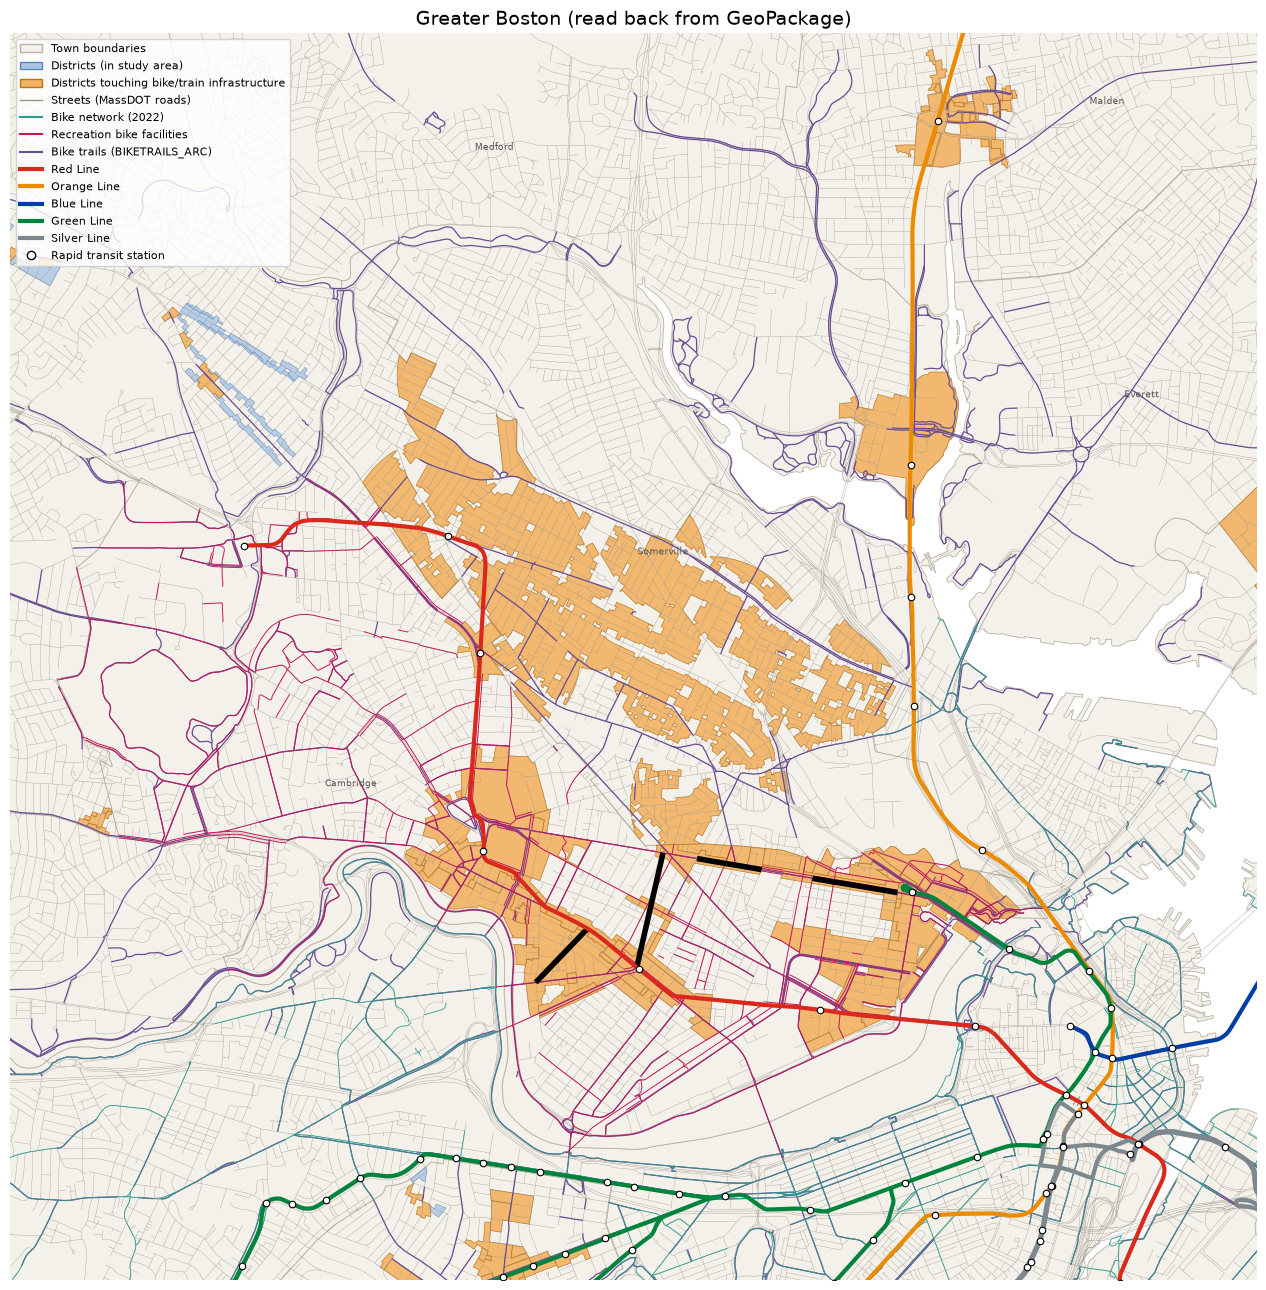

In [27]:
gpkg_layers = {name: gpd.read_file(gpkg, layer=name) for name in gpd.list_layers(gpkg)["name"]}
for name, g in gpkg_layers.items():
    print(f"{name:15s} {len(g):5d} features  crs={g.crs.to_string()}")

g_bike, g_lines, g_stations = gpkg_layers["bike_network"], gpkg_layers["mbta_lines"], gpkg_layers["mbta_stations"]
g_districts, g_towns = gpkg_layers["districts"], gpkg_layers["towns"]
g_bike2, g_trails = gpkg_layers["bike_recreation"], gpkg_layers["bike_trails"]
g_roads = gpkg_layers["roads"]

# Extent: all bike + train infrastructure plus a margin
minx, miny, maxx, maxy = pd.concat(
    [g_bike.geometry, g_lines.geometry, g_stations.geometry], ignore_index=True
).total_bounds
pad = 5000 #1500

fig, ax = plt.subplots(figsize=(13, 13))

g_towns.plot(ax=ax, facecolor="#f4f1ea", edgecolor="#b8b2a3", linewidth=0.6, zorder=1)
g_districts[~g_districts.touches_infra].plot(ax=ax, facecolor="#a8c5e6", edgecolor="#5b86b5", linewidth=0.4, alpha=0.8, zorder=2)
g_districts[g_districts.touches_infra].plot(ax=ax, facecolor="#f2b263", edgecolor="#b8741a", linewidth=0.5, alpha=0.9, zorder=3)
g_roads.plot(ax=ax, color="#9a958a", linewidth=0.25, zorder=3.5)
g_trails.plot(ax=ax, color="#6a4c93", linewidth=0.9, zorder=4)
g_bike.plot(ax=ax, color="#2a9d8f", linewidth=0.6, zorder=4)
g_bike2.plot(ax=ax, color="#c2185b", linewidth=0.7, zorder=4)
for line, color in LINE_COLORS.items():
    g_lines[g_lines.LINE == line].plot(ax=ax, color=color, linewidth=3, zorder=5)
g_stations.plot(ax=ax, color="white", edgecolor="black", markersize=22, linewidth=0.8, zorder=6)

for _, row in g_towns.iterrows():
    p = row.geometry.representative_point()
    if minx - pad < p.x < maxx + pad and miny - pad < p.y < maxy + pad:
        ax.annotate(row.TOWN.title(), (p.x, p.y), ha="center", fontsize=6.5, color="#555", zorder=7)


## target plot

# Cambridge streets only
# cambridge = g_roads[g_roads.MGIS_TOWN.str.upper() == "CAMBRIDGE"]
# name = cambridge.STREETNAME.fillna("").str.upper()
# cambridge_st = cambridge[name == "CAMBRIDGE STREET"]
# prospect_st = cambridge[name == "PROSPECT STREET"]
# willow_st = cambridge[name == "WILLOW STREET"]

# # Merge the many Cambridge St segments into continuous lines
# merged = linemerge(cambridge_st.geometry.union_all())
# parts = list(merged.geoms) if hasattr(merged, "geoms") else [merged]

# # Where each cross street meets Cambridge St
# pt_prospect = prospect_st.geometry.union_all().intersection(merged)
# pt_willow = willow_st.geometry.union_all().intersection(merged)

# # Cut Cambridge St between the two intersections
# part = next(p for p in parts if p.distance(pt_prospect) < 1 and p.distance(pt_willow) < 1)
# d1, d2 = sorted([part.project(pt_prospect), part.project(pt_willow)])

# # The segment as a GeoDataFrame (same CRS as the roads layer)
# segment = gpd.GeoDataFrame(
#     {
#         "STREETNAME": ["CAMBRIDGE STREET"],
#         "FROM_ST": ["PROSPECT STREET"],
#         "TO_ST": ["WILLOW STREET"],
#         "MGIS_TOWN": ["CAMBRIDGE"],
#         "PROJECT": ["Cambridge Street Safety Improvement Project"],
#         "LENGTH_M": [d2 - d1],
#     },
#     geometry=[substring(part, d1, d2)],
#     crs=g_roads.crs,
# )
# segment["LENGTH_MI"] = segment.LENGTH_M / 1609.344
# print(segment.drop(columns="geometry"))

# Optional: save it as its own layer
# segment.to_file("output/cambridge_st_prospect_to_willow.gpkg", layer="segment", driver="GPKG")

# Plot
# fig, ax = plt.subplots(figsize=(10, 10))
# cambridge.plot(ax=ax, color="#c8c4ba", linewidth=0.8, zorder=1)                 # other Cambridge streets
# cambridge_st.plot(ax=ax, color="#8a8578", linewidth=1.5, zorder=2)               # rest of Cambridge St
# prospect_st.plot(ax=ax, color="#2a9d8f", linewidth=2, zorder=3, label="Prospect St")
# willow_st.plot(ax=ax, color="#c2185b", linewidth=2, zorder=3, label="Willow St")
cambridge = g_roads[g_roads.MGIS_TOWN.str.upper() == "CAMBRIDGE"]
seg1 = gis.street_segment_from_intersections(cambridge, target_street="CAMBRIDGE STREET", start_street="PROSPECT STREET", end_street="WILLOW STREET", project="Cambridge Street Safety Improvement Project")
seg2 = gis.street_segment_from_intersections(cambridge, target_street="CAMBRIDGE STREET", start_street="FULKERSON STREET", end_street="SECOND STREET", project="Cambridge Street Safety Improvement Project")
seg3 = gis.segment_from_intersections(cambridge, "PUTNAM AVENUE", "WESTERN AVENUE", "HANCOCK STREET", "MASSACHUSETTS AVENUE", name="test_name", project="test_project")
seg4 = gis.segment_from_intersections(cambridge, "HAMPSHIRE STREET", "CAMBRIDGE STREET", "PROSPECT STREET", "MASSACHUSETTS AVENUE", name="test_name", project="test_project")
new_segments = pd.concat([seg1, seg2, seg3, seg4], ignore_index=True)
new_segments.plot(ax=ax, color="black", linewidth=4, zorder=4, label="Cambridge St (Prospect to Willow)")
# gpd.GeoSeries([pt_prospect, pt_willow], crs=g_roads.crs).plot(ax=ax, color="white", edgecolor="black",
#                                                             markersize=60, zorder=5)

##


# ax.set_xlim(minx - pad, maxx + pad)
# ax.set_ylim(miny - pad, maxy + pad)
centerx = 232591; centery = 904240;#miny = 894240;maxy = 894240;
ax.set_xlim(centerx - pad, centerx + pad)
ax.set_ylim(centery - pad, centery + pad)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Greater Boston (read back from GeoPackage)", fontsize=14)
ax.legend(handles=handles, loc="upper left", fontsize=8, frameon=True)
plt.tight_layout()
plt.show()